# What Happens to a Medical Image Before and After the Model Sees It

Companion notebook for the freeCodeCamp article.

**The image.** One pediatric chest X-ray, used throughout. It already carries a real
example of burned-in annotation: the `R` laterality marker in the top left, placed by
the radiographer to indicate the patient's right side.

In [4]:
# pydicom is preinstalled on Kaggle. This line is for everywhere else.
!pip install -q pydicom 2>/dev/null || pip install -q pydicom --break-system-packages

In [5]:
import glob, os
import numpy as np
import matplotlib.pyplot as plt
import cv2
from scipy import ndimage
from skimage.exposure import match_histograms

import pydicom
from pydicom.dataset import Dataset, FileMetaDataset
from pydicom.uid import (ExplicitVRLittleEndian, generate_uid,
                         SecondaryCaptureImageStorage)

plt.rcParams["figure.dpi"] = 110

TEAL = np.array([0.10, 0.80, 0.80])
CORAL = "#e07a5f"


def show(*panels, figsize=None, cmap="gray"):
    """panels: (array, title) pairs."""
    n = len(panels)
    fig, ax = plt.subplots(1, n, figsize=figsize or (3.7 * n, 4.0))
    ax = np.atleast_1d(ax)
    for a, (arr, title) in zip(ax, panels):
        a.imshow(arr, cmap=None if arr.ndim == 3 else cmap)
        a.set_title(title, fontsize=10)
        a.axis("off")
    plt.tight_layout()
    plt.show()


def overlay(gray, mask, colour=TEAL, alpha=0.45):
    out = np.dstack([gray] * 3).astype(float) / 255
    out[mask > 0] = (1 - alpha) * out[mask > 0] + alpha * colour
    return out

## The image

The X-ray is embedded in this notebook as base64 text. The image is resized to 512 pixels tall, and its original width is scaled proportionally.

In [6]:
IMAGE_B64 = (
    "..."
)

decoded from the notebook itself: 722 x 512 pixels
aspect ratio 1.41 — kept as it was, not forced to a square


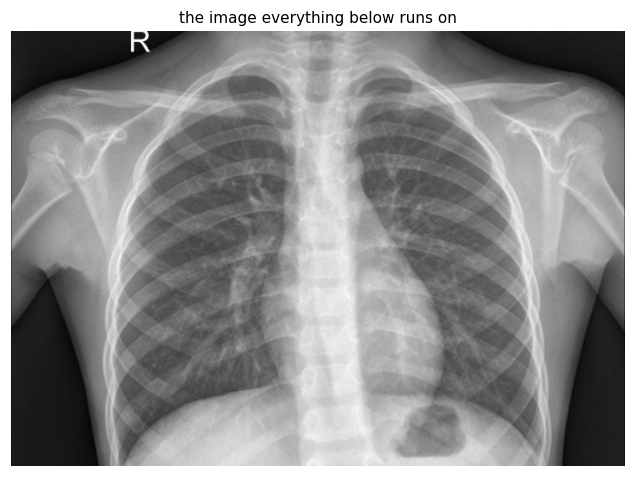

In [7]:
import base64

buffer = np.frombuffer(base64.b64decode(IMAGE_B64), np.uint8)
img = cv2.imdecode(buffer, cv2.IMREAD_GRAYSCALE)
H, W = img.shape

print(f"decoded from the notebook itself: {W} x {H} pixels")
print(f"aspect ratio {W / H:.2f} — kept as it was, not forced to a square")

show((img, "the image everything below runs on"), figsize=(6, 4.4))

## 1. Acquisition

A DICOM file is pixels plus several hundred labelled fields describing which machine
made the image, how, and of whom.

This image arrived as a JPEG, so those fields are already gone. Wrapping it back into a
DICOM here with invented identifiers gives section 2 something to de-identify. 

In [8]:
def make_synthetic_dicom(pixels, path="synthetic_cxr.dcm"):
    """Every identifier below is invented. No real patient data is involved."""
    fm = FileMetaDataset()
    fm.MediaStorageSOPClassUID = SecondaryCaptureImageStorage
    fm.MediaStorageSOPInstanceUID = generate_uid()
    fm.TransferSyntaxUID = ExplicitVRLittleEndian

    ds = Dataset()
    ds.file_meta = fm

    # --- identifies the patient ---
    ds.PatientName = "DOE^JANE"
    ds.PatientID = "4471902"
    ds.PatientBirthDate = "20090311"
    ds.PatientSex = "F"
    ds.InstitutionName = "St Elsewhere General"
    ds.ReferringPhysicianName = "SMITH^ROBERT"
    ds.StudyDate = "20190418"
    ds.StudyTime = "104512"
    ds.AccessionNumber = "ACC00918273"

    # --- describes the image ---
    ds.Modality = "DX"
    ds.BodyPartExamined = "CHEST"
    ds.ViewPosition = "AP"
    ds.PatientAge = "010Y"
    ds.Manufacturer = "Acme Imaging"
    ds.ManufacturerModelName = "PortaRad 200"
    ds.KVP = "70"
    ds.Exposure = "2"
    ds.PixelSpacing = [0.520, 0.520]          # mm per pixel at this resolution

    ds.StudyInstanceUID = generate_uid()
    ds.SeriesInstanceUID = generate_uid()
    ds.SOPInstanceUID = fm.MediaStorageSOPInstanceUID
    ds.SOPClassUID = SecondaryCaptureImageStorage

    ds.SamplesPerPixel = 1
    ds.PhotometricInterpretation = "MONOCHROME2"
    ds.Rows, ds.Columns = pixels.shape
    ds.BitsAllocated = ds.BitsStored = 8
    ds.HighBit = 7
    ds.PixelRepresentation = 0
    ds.PixelData = pixels.tobytes()

    ds.save_as(path, enforce_file_format=True)
    return path


ds = pydicom.dcmread(make_synthetic_dicom(img))

for tag in ["Modality", "BodyPartExamined", "ViewPosition", "PatientAge",
            "Manufacturer", "ManufacturerModelName", "KVP", "PixelSpacing"]:
    print(f"{tag:24s} {ds[tag].value}")

covered = ds.Rows * float(ds.PixelSpacing[0])
print(f"\nimage covers {covered:.0f} mm of the patient vertically")
print("two images can have identical pixel dimensions and cover completely")
print("different amounts of anatomy. measure in pixels, ignore PixelSpacing,")
print("and the measurement is wrong.")

Modality                 DX
BodyPartExamined         CHEST
ViewPosition             AP
PatientAge               010Y
Manufacturer             Acme Imaging
ManufacturerModelName    PortaRad 200
KVP                      70
PixelSpacing             [0.52, 0.52]

image covers 266 mm of the patient vertically
two images can have identical pixel dimensions and cover completely
different amounts of anatomy. measure in pixels, ignore PixelSpacing,
and the measurement is wrong.


## 2. Anonymization, de-identification, pseudonymization

The dividing question is whether a key exists that maps back to the patient.

- **Pseudonymization** — identifier replaced with a code, key retained
- **De-identification** — identifying information removed
- **Anonymization** — meant to be one-way, no key

Two separate problems: identifiers in the header, and identifiers in the pixels.

In [9]:
print("--- before ---")
for tag in ["PatientName", "PatientID", "PatientBirthDate",
            "InstitutionName", "StudyDate", "AccessionNumber"]:
    print(f"{tag:22s} {ds[tag].value}")

--- before ---
PatientName            DOE^JANE
PatientID              4471902
PatientBirthDate       20090311
InstitutionName        St Elsewhere General
StudyDate              20190418
AccessionNumber        ACC00918273


In [10]:
IDENTIFIERS = ["PatientName", "PatientID", "PatientBirthDate", "PatientSex",
               "InstitutionName", "ReferringPhysicianName",
               "StudyDate", "StudyTime", "AccessionNumber"]


def scrub_header(dataset):
    out = dataset.copy()
    for tag in IDENTIFIERS:
        if tag in out:
            out[tag].value = ""
    out.PatientIdentityRemoved = "YES"
    out.DeidentificationMethod = "demo - not a compliant profile"
    return out


def pseudonymize_header(dataset, code):
    """ Same as scrubbing, but a code goes in and somebody keeps the mapping."""
    out = scrub_header(dataset)
    out.PatientID = code
    out.PatientName = code
    return out


clean_ds = scrub_header(ds)

print("--- after ---")
for tag in ["PatientName", "PatientID", "StudyDate", "AccessionNumber"]:
    print(f"{tag:22s} {clean_ds[tag].value!r}")

print(f"\nkept on purpose: {clean_ds.Modality}, {clean_ds.ViewPosition}, "
      f"{clean_ds.PixelSpacing}, age {clean_ds.PatientAge}")
print("those describe the image, not the patient, and downstream code needs them")

--- after ---
PatientName            ''
PatientID              ''
StudyDate              ''
AccessionNumber        ''

kept on purpose: DX, AP, [0.52, 0.52], age 010Y
those describe the image, not the patient, and downstream code needs them


### The pixels are a separate problem

The header is clean. The `R` marker is still in the image.

Here it is only a laterality marker, which is not identifying. But it sits in the same
corner where a scanner writes patient name, date of birth, and accession number, and it
was drawn the same way. Anything that finds one finds the other.

A naive approach: look for small bright blobs near the top of the image.

bright blobs in the top strip at >200: 11
same search at >230                 : 1

  x[141-162]  y[  0- 23]  area 198
  x[331-335]  y[ 22- 29]  area 19
  x[391-395]  y[ 24- 28]  area 20
  x[381-399]  y[ 47- 73]  area 205
  x[321-341]  y[ 51- 70]  area 167
  x[483-532]  y[ 60-101]  area 371
  x[335-348]  y[ 70- 94]  area 163
  x[187-217]  y[ 73- 93]  area 229
  x[367-382]  y[ 77-101]  area 157
  x[382-390]  y[ 81- 95]  area 77
  x[168-179]  y[ 84- 88]  area 31


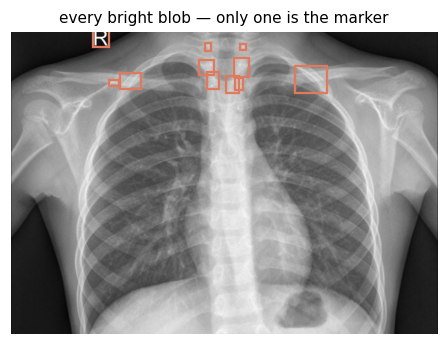

In [11]:
px = clean_ds.pixel_array.copy()

top = np.zeros_like(px, bool)
top[:int(0.20 * H), :] = True

candidates = ndimage.label((px > 200) & top)[0]
boxes = []
for i in range(1, candidates.max() + 1):
    ys, xs = np.where(candidates == i)
    if 15 < len(ys) < 3000:
        boxes.append((xs.min(), ys.min(), xs.max(), ys.max(), len(ys)))

print(f"bright blobs in the top strip at >200: {len(boxes)}")
strict = ndimage.label((px > 230) & top)[0]
n_strict = sum(1 for i in range(1, strict.max() + 1)
               if 15 < (strict == i).sum() < 3000)
print(f"same search at >230                 : {n_strict}")
print()
for x0, y0, x1, y1, area in boxes:
    print(f"  x[{x0:3d}-{x1:3d}]  y[{y0:3d}-{y1:3d}]  area {area}")

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(px, cmap="gray")
for x0, y0, x1, y1, _ in boxes:
    ax.add_patch(plt.Rectangle((x0 - 3, y0 - 3), x1 - x0 + 6, y1 - y0 + 6,
                               fill=False, ec=CORAL, lw=1.5))
ax.set_title("every bright blob — only one is the marker", fontsize=10)
ax.axis("off"); plt.show()

Most of those are bone: clavicle, ribs, the head of the humerus. All bright, all near
the top, none of them text.

Raising the threshold to 230 happens to leave only the marker on this image, which looks
like a fix until you try the next image and find bone that is brighter, or a marker that
is dimmer. No threshold works everywhere.

This is why real de-identification runs OCR rather than a brightness rule. Text has
structure a blob detector cannot see. Below, the marker is picked out by knowing roughly
where it sits in this one image, which is not a method that generalises either.

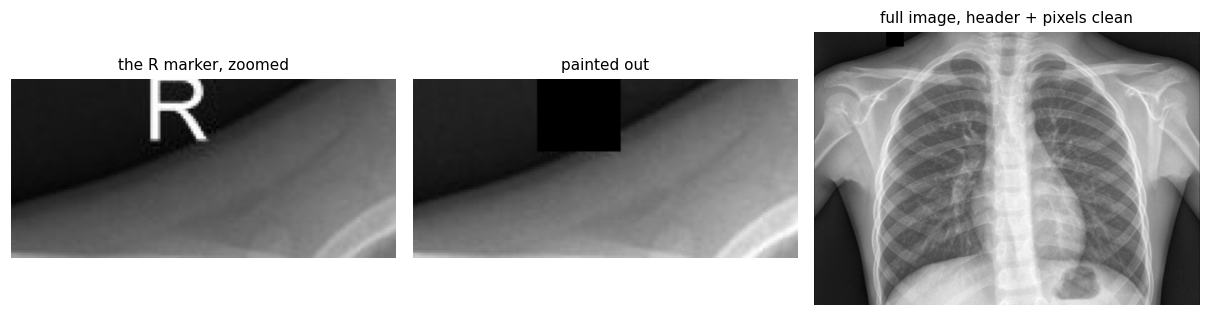

redacted region: x[135-168]  y[0-29]


In [12]:
marker = min(boxes, key=lambda b: b[0])           # leftmost blob, for this image only
x0, y0, x1, y1, _ = marker
pad = 6

ry0, ry1 = max(0, y0 - pad), min(px.shape[0], y1 + pad)
rx0, rx1 = max(0, x0 - pad), min(px.shape[1], x1 + pad)

redacted = px.copy()
redacted[ry0:ry1, rx0:rx1] = 0

crop = (slice(0, int(0.14 * H)), slice(int(0.12 * W), int(0.33 * W)))
show((px[crop], "the R marker, zoomed"),
     (redacted[crop], "painted out"),
     (redacted, "full image, header + pixels clean"))

print(f"redacted region: x[{rx0}-{rx1}]  y[{ry0}-{ry1}]")

Not real text detection. Picking the leftmost blob works on this image and nothing
   else. Production pipelines use OCR.

For de-identification beyond a demo:
[Aegis](https://github.com/lakshmi-mahabaleshwara/aegis), which uses EasyOCR for the
pixels and PS3.15 profiles for the header.

## 3. Preprocessing

Resizing, windowing, and orientation. Windowing picks a range of pixel values and maps
it to the visible range, discarding the rest. Radiologists do this constantly, the same
scan gets one window for lung and another for bone.

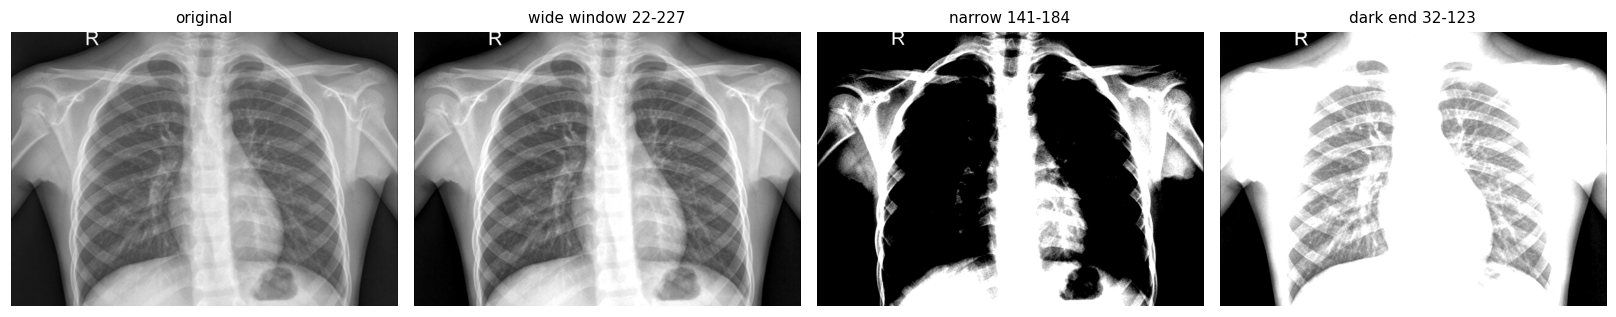

resize (512, 722) -> (256, 361)
pixel spacing follows: 0.520 mm -> 1.040 mm
the pixels changed, the patient did not


In [13]:
lo, hi = np.percentile(img, [2, 98])
wide = np.clip((img.astype(float) - lo) / (hi - lo), 0, 1)

lo2, hi2 = np.percentile(img, [55, 80])          # narrow: soft tissue only
narrow = np.clip((img.astype(float) - lo2) / (hi2 - lo2), 0, 1)

lo3, hi3 = np.percentile(img, [10, 45])          # dark end: lung detail
lung_win = np.clip((img.astype(float) - lo3) / (hi3 - lo3), 0, 1)

show((img, "original"),
     (wide, f"wide window {lo:.0f}-{hi:.0f}"),
     (narrow, f"narrow {lo2:.0f}-{hi2:.0f}"),
     (lung_win, f"dark end {lo3:.0f}-{hi3:.0f}"))

half = cv2.resize(img, (W // 2, H // 2), interpolation=cv2.INTER_AREA)
print(f"resize {img.shape} -> {half.shape}")
print(f"pixel spacing follows: 0.520 mm -> {0.520 * 2:.3f} mm")
print("the pixels changed, the patient did not")

## 4. Normalization

Putting pixel values into a consistent numerical range, which makes different *sources* agree.

original   min    3.00  max  255.00  mean 131.00  std 56.92
min-max    min    0.00  max    1.00  mean   0.51  std  0.23
z-score    min   -2.25  max    2.18  mean  -0.00  std  1.00


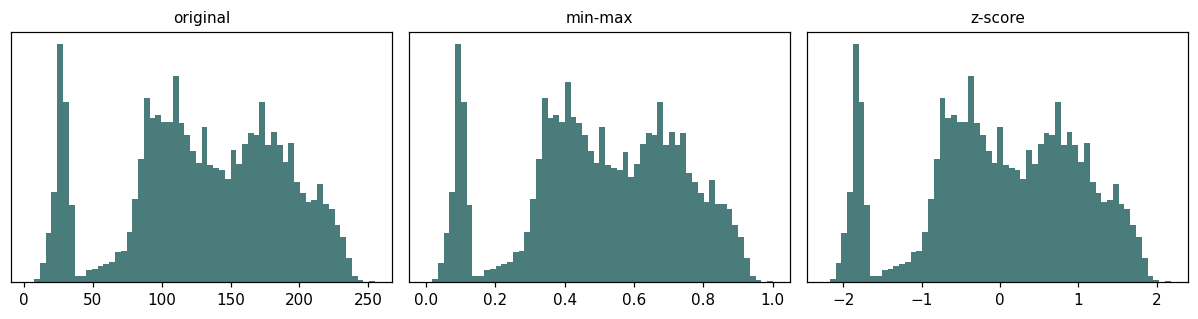

In [14]:
f = img.astype(np.float32)

minmax = (f - f.min()) / (f.max() - f.min())
zscore = (f - f.mean()) / f.std()

for name, d in [("original", f), ("min-max", minmax), ("z-score", zscore)]:
    print(f"{name:10s} min {d.min():7.2f}  max {d.max():7.2f}  "
          f"mean {d.mean():6.2f}  std {d.std():5.2f}")

fig, ax = plt.subplots(1, 3, figsize=(11, 3))
for a, d, t in zip(ax, [f, minmax, zscore], ["original", "min-max", "z-score"]):
    a.hist(d.ravel(), bins=60, color="#4a7c7c")
    a.set_title(t, fontsize=10); a.set_yticks([])
plt.tight_layout(); plt.show()

Min-max is defined by exactly two pixels, the darkest and the brightest. One bright
artifact is enough to squash everything else into a narrow band.

Simulating one below: a small metal object, which in a real pediatric chest film could
be a pacemaker, an ECG lead, or a button on a gown.

In [15]:
spiked = f.copy()
spiked[int(0.30 * H):int(0.32 * H), int(0.42 * W):int(0.44 * W)] = 4000

mm_spiked = (spiked - spiked.min()) / (spiked.max() - spiked.min())
z_spiked = (spiked - spiked.mean()) / spiked.std()

patch = (slice(int(0.45 * H), int(0.80 * H)),
         slice(int(0.22 * W), int(0.42 * W)))     # a lung region, no artifact in it

print(f"min-max, no artifact : tissue spans {minmax[patch].min():.3f} to {minmax[patch].max():.3f}")
print(f"min-max, artifact    : tissue spans {mm_spiked[patch].min():.3f} to {mm_spiked[patch].max():.3f}")
print()
print(f"z-score, no artifact : tissue spans {zscore[patch].min():.2f} to {zscore[patch].max():.2f}")
print(f"z-score, artifact    : tissue spans {z_spiked[patch].min():.2f} to {z_spiked[patch].max():.2f}")
print()
print("min-max collapsed the real anatomy. z-score uses every pixel, so one outlier")
print("barely moves it.")

min-max, no artifact : tissue spans 0.246 to 0.659
min-max, artifact    : tissue spans 0.016 to 0.042

z-score, no artifact : tissue spans -1.16 to 0.67
z-score, artifact    : tissue spans -0.71 to 0.39

min-max collapsed the real anatomy. z-score uses every pixel, so one outlier
barely moves it.


## 5. Annotation and label

A **label** is a word for the whole image. An **annotation** is drawn, and carries
location.

A real annotation would be traced by a radiologist. This image does not come with one,
so the mask below is produced automatically by thresholding; lungs hold air, so they
are darker than the surrounding tissue.

Annotations are expensive precisely because they need a trained human, and an
automatic approximation is not the same thing.

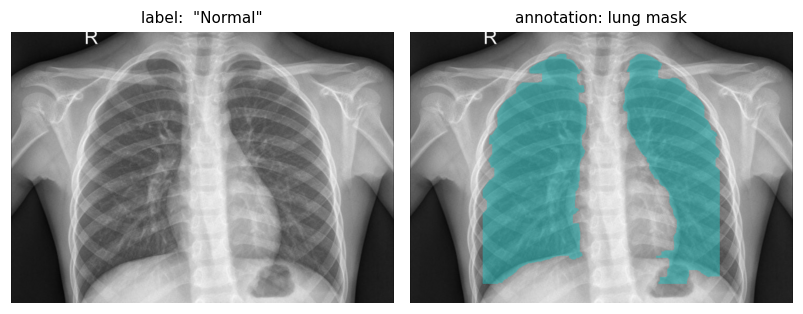

label      : 1 word describing 369,664 pixels
annotation : 108,457 pixels marked individually (29.3% of the image)


In [16]:
def rough_lung_mask(gray, threshold=145):
    """Dark regions inside a central box. Crude on purpose — section 8 cleans it."""
    smooth = cv2.GaussianBlur(gray, (7, 7), 0)
    h, w = gray.shape
    roi = np.zeros_like(gray, bool)
    roi[int(0.05 * h):int(0.93 * h), int(0.19 * w):int(0.81 * w)] = True
    m = ((smooth < threshold) & roi).astype(np.uint8)
    return cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))


def clean_lung_mask(rough):
    labelled, n = ndimage.label(rough)
    ids, counts = np.unique(labelled[labelled > 0], return_counts=True)
    keep = ids[np.argsort(counts)[-2:]]                   # two largest — two lungs
    m = np.isin(labelled, keep)
    m = ndimage.binary_closing(m, np.ones((15, 15)))
    return ndimage.binary_fill_holes(m).astype(np.uint8) * 255


rough_mask = rough_lung_mask(img)
lung_mask = clean_lung_mask(rough_mask)

label = "Normal"        # a word — no location

show((img, f'label:  "{label}"'),
     (overlay(img, lung_mask), "annotation: lung mask"))

print(f"label      : 1 word describing {img.size:,} pixels")
print(f"annotation : {(lung_mask > 0).sum():,} pixels marked individually "
      f"({(lung_mask > 0).mean():.1%} of the image)")

## 6. Classification, detection, segmentation

Same image, three kinds of answer. *Is it there* / *where roughly* / *which exact pixels*.
Difficulty rises in that order, and so does the annotation effort needed to train it.

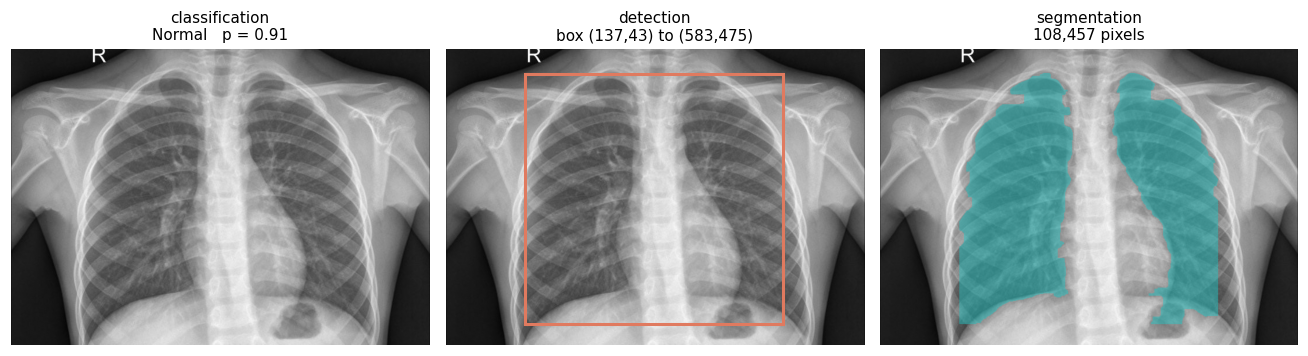

what a human has to produce per image:
  classification   1 word
  detection        4 numbers
  segmentation     a traced outline


In [17]:
cls_label, cls_prob = "Normal", 0.91

ys, xs = np.where(lung_mask > 0)
bx0, by0, bx1, by1 = xs.min(), ys.min(), xs.max(), ys.max()

fig, ax = plt.subplots(1, 3, figsize=(12, 4.4))

ax[0].imshow(img, cmap="gray")
ax[0].set_title(f"classification\n{cls_label}   p = {cls_prob}", fontsize=10)

ax[1].imshow(img, cmap="gray")
ax[1].add_patch(plt.Rectangle((bx0, by0), bx1 - bx0, by1 - by0,
                              fill=False, ec=CORAL, lw=2))
ax[1].set_title(f"detection\nbox ({bx0},{by0}) to ({bx1},{by1})", fontsize=10)

ax[2].imshow(overlay(img, lung_mask))
ax[2].set_title(f"segmentation\n{(lung_mask > 0).sum():,} pixels", fontsize=10)

for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

print("what a human has to produce per image:")
print("  classification   1 word")
print("  detection        4 numbers")
print("  segmentation     a traced outline")

## 7. Augmentation

Augmentation creates new training examples by transforming existing images. The test: could the transformed image
have come from a real scanner, from a real patient, and still have the same correct answer?

The horizontal flip fails that test. Look at where the `R` marker ends up.

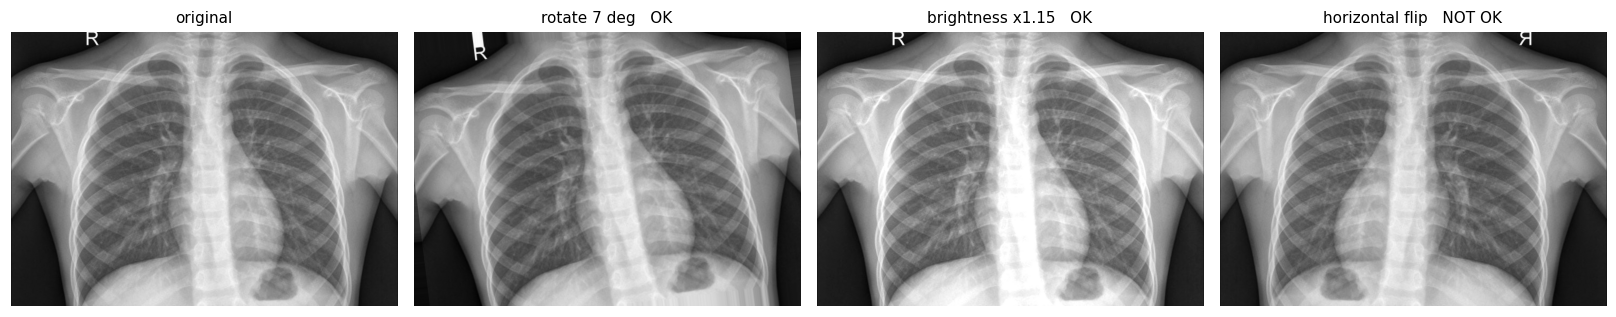

the flip moves the heart to the right side of the body. that is dextrocardia,
a real condition — so the image stays anatomically plausible while the label
still says 'Normal'.

look at the marker too. it is now on the left, labelling the wrong side, and
it reads as a mirrored letter. a radiographer would spot that instantly.
a convolutional network has no reason to.


In [18]:
h, w = img.shape
M = cv2.getRotationMatrix2D((w // 2, h // 2), 7, 1.0)
rotated = cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REPLICATE)
brighter = np.clip(img.astype(float) * 1.15, 0, 255).astype(np.uint8)
flipped = img[:, ::-1]

show((img, "original"),
     (rotated, "rotate 7 deg   OK"),
     (brighter, "brightness x1.15   OK"),
     (flipped, "horizontal flip   NOT OK"))

print("the flip moves the heart to the right side of the body. that is dextrocardia,")
print("a real condition — so the image stays anatomically plausible while the label")
print("still says 'Normal'.")
print()
print("look at the marker too. it is now on the left, labelling the wrong side, and")
print("it reads as a mirrored letter. a radiographer would spot that instantly.")
print("a convolutional network has no reason to.")

## 8. Postprocessing

Cleaning model output. The rough mask from section 5 is a good example; a threshold
produces roughly the right shape plus a lot of debris.

Two standard fixes: keep the largest components and fill holes.

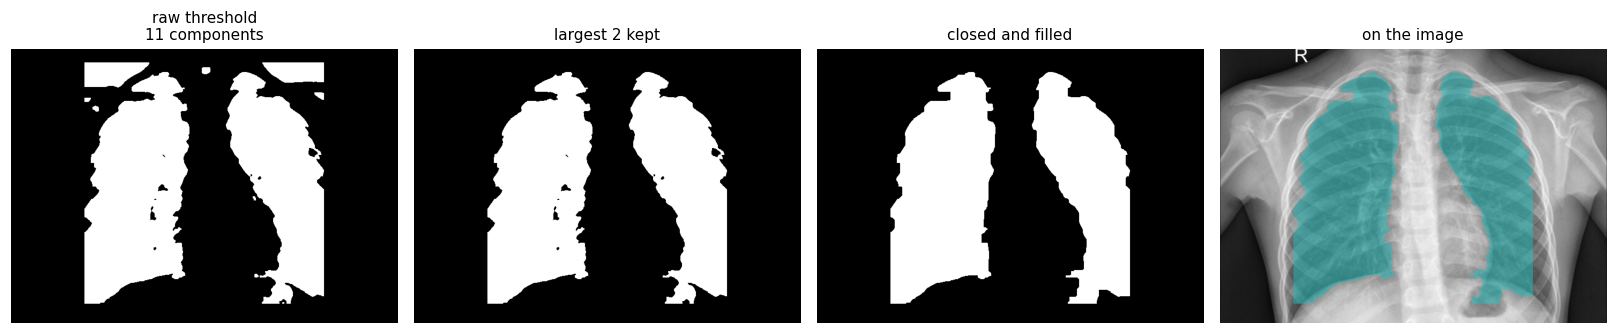

components   11  ->  2
area         31.1%  ->  29.3%

'a person has two lungs' is anatomical knowledge applied outside the model.
often cheaper than making a model learn it.


In [19]:
labelled, n_components = ndimage.label(rough_mask)
ids, counts = np.unique(labelled[labelled > 0], return_counts=True)
largest_two = np.isin(labelled, ids[np.argsort(counts)[-2:]])
filled = ndimage.binary_fill_holes(
    ndimage.binary_closing(largest_two, np.ones((15, 15))))

show((rough_mask, f"raw threshold\n{n_components} components"),
     (largest_two, "largest 2 kept"),
     (filled, "closed and filled"),
     (overlay(img, filled * 255), "on the image"))

print(f"components   {n_components}  ->  2")
print(f"area         {(rough_mask > 0).mean():.1%}  ->  {filled.mean():.1%}")
print()
print("'a person has two lungs' is anatomical knowledge applied outside the model.")
print("often cheaper than making a model learn it.")

In [20]:
changed = ((rough_mask > 0) != (filled > 0)).mean()

print(f"pixels the cleanup changed : {changed:.1%}")
print(f"component count            : {n_components}  ->  2")
print()
print("the cleanup touched a small fraction of pixels but changed the structure")
print("completely. a score that counts pixels would barely register the difference;")
print("one that counts regions would call the raw output badly wrong.")
print()
print("pick a metric that can see the mistakes you care about.")

pixels the cleanup changed : 3.0%
component count            : 11  ->  2

the cleanup touched a small fraction of pixels but changed the structure
completely. a score that counts pixels would barely register the difference;
one that counts regions would call the raw output badly wrong.

pick a metric that can see the mistakes you care about.


The warning: if model output needs this much cleanup to look reasonable, the cleanup is
doing work the model should be doing. Look at the raw output too.

## 9. Harmonization

Making images from different sources comparable. Normalization fixes one image's value
range. Harmonization makes two *sources* agree.

Only one image is available here, so the second site is simulated, the same X-ray put
through a gamma and contrast change, standing in for a different vendor's default
processing. The transform is invented; the failure mode it demonstrates is not.

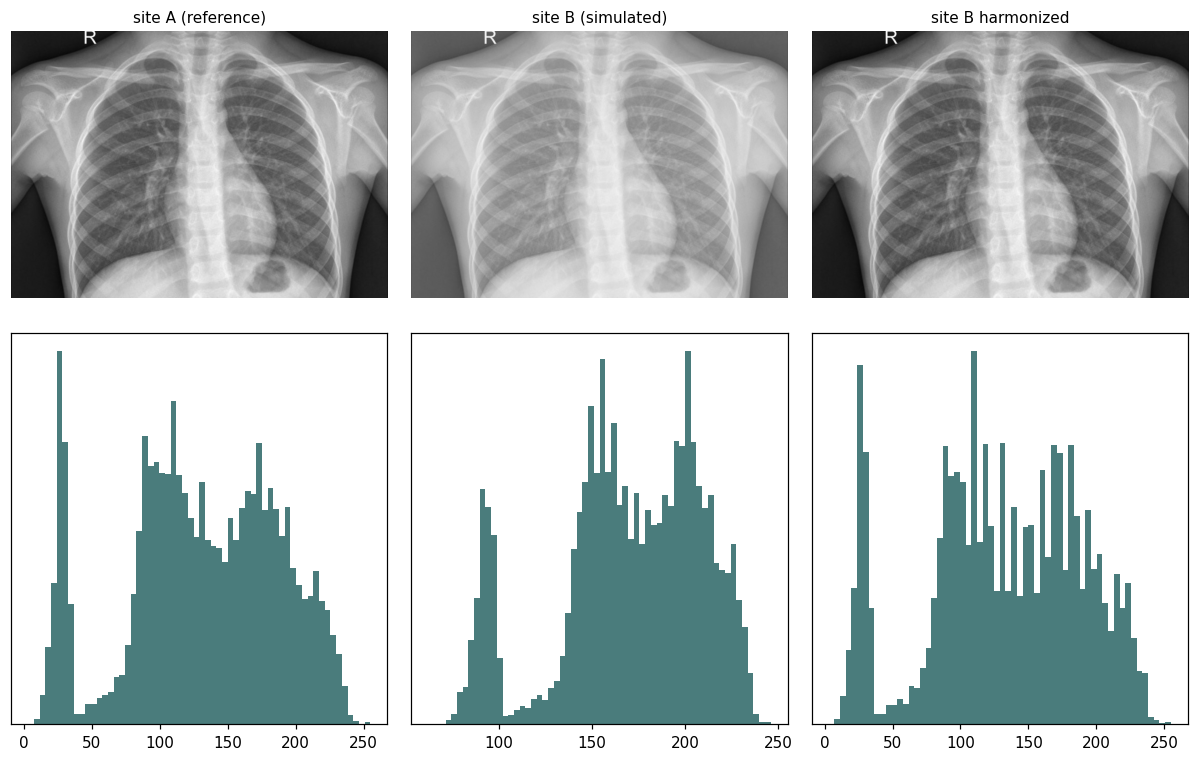

site A       mean  131.0   std  56.9
site B       mean  169.9   std  39.4
harmonized   mean  131.3   std  57.0


In [21]:
def simulate_other_scanner(gray, gamma=0.72, contrast=0.75, brightness=1.18):
    f = (gray.astype(np.float32) / 255) ** gamma
    f = (f - 0.5) * contrast + 0.5 * brightness
    return (np.clip(f, 0, 1) * 255).astype(np.uint8)


site_a = img
site_b = simulate_other_scanner(img)
harmonized = np.asarray(match_histograms(site_b, site_a)).astype(np.uint8)

fig, ax = plt.subplots(2, 3, figsize=(11, 7.4))
for a, d, t in zip(ax[0], [site_a, site_b, harmonized],
                   ["site A (reference)", "site B (simulated)", "site B harmonized"]):
    a.imshow(d, cmap="gray", vmin=0, vmax=255)
    a.set_title(t, fontsize=10); a.axis("off")
for a, d in zip(ax[1], [site_a, site_b, harmonized]):
    a.hist(d.ravel(), bins=60, color="#4a7c7c"); a.set_yticks([])
plt.tight_layout(); plt.show()

for name, d in [("site A", site_a), ("site B", site_b), ("harmonized", harmonized)]:
    print(f"{name:12s} mean {d.mean():6.1f}   std {d.std():5.1f}")

Histogram matching handles brightness and contrast. It does not handle differences in
resolution, noise, or vendor processing, and it cannot recover information that was
thrown away before you received the file.

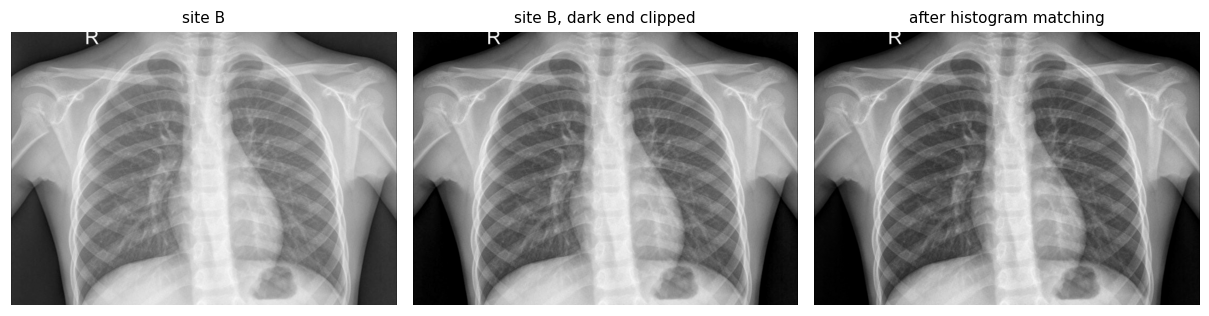

pixels crushed to zero    : 4.2%
distinct values, site B   : 178
distinct values, clipped  : 157
distinct values, matched  : 157

matching rescales what survived. it does not bring back what was lost.


In [22]:
clipped = np.clip(site_b.astype(float) - 90, 0, 255).astype(np.uint8)
recovered = np.asarray(match_histograms(clipped, site_a)).astype(np.uint8)

show((site_b, "site B"),
     (clipped, "site B, dark end clipped"),
     (recovered, "after histogram matching"))

print(f"pixels crushed to zero    : {(clipped == 0).mean():.1%}")
print(f"distinct values, site B   : {len(np.unique(site_b))}")
print(f"distinct values, clipped  : {len(np.unique(clipped))}")
print(f"distinct values, matched  : {len(np.unique(recovered))}")
print()
print("matching rescales what survived. it does not bring back what was lost.")

Everything above ran on a single chest X-ray. The vocabulary is the point, not the model.